# 00 — What is a spectrum?

**Goal:** understand what a power spectrum shows, on a signal we build ourselves, so we know the answer in advance.

The EEG in notebook 01 is messy. Here we start with a pure 10 Hz wave, add noise, and watch what the spectrum does.
If this is clear, the eyes-closed result becomes obvious: it is the same thing, only noisier.

No data download: everything is generated with NumPy.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import welch

SFREQ = 160       # samples per second, same as the PhysioNet recordings
DURATION = 4      # seconds
FREQ = 10         # Hz, frequency of the wave we hide in the signal
AMPLITUDE = 50    # µV, size of the wave
NOISE = 20        # µV, size of the random noise added on top
ALPHA = (8, 12)   # Hz, the band we will measure

## 1. Build a signal

A sine wave is the simplest possible oscillation: `AMPLITUDE * sin(2π · FREQ · t)` goes up and down `FREQ` times per second.
Random noise is added so the signal looks a bit like real EEG.

640 samples. Count the peaks in one second of the top plot: there should be 10.


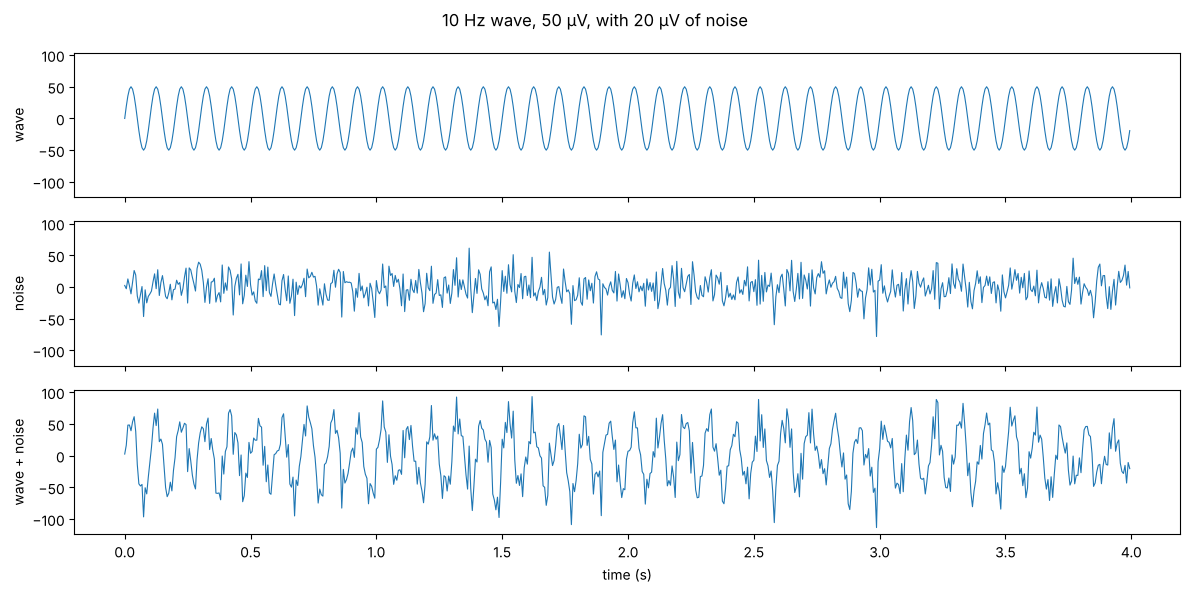

In [2]:
rng = np.random.default_rng(0)  # fixed seed: same noise every run
t = np.arange(0, DURATION, 1 / SFREQ)  # one time stamp per sample

wave = AMPLITUDE * np.sin(2 * np.pi * FREQ * t)
noise = NOISE * rng.standard_normal(len(t))
signal = wave + noise

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, (name, y) in zip(axes, {"wave": wave, "noise": noise, "wave + noise": signal}.items()):
    ax.plot(t, y, lw=0.8)
    ax.set_ylabel(name)
axes[-1].set_xlabel("time (s)")
fig.suptitle(f"{FREQ} Hz wave, {AMPLITUDE} µV, with {NOISE} µV of noise")
fig.tight_layout()

print(f"{len(t)} samples. Count the peaks in one second of the top plot: there should be {FREQ}.")

## 2. The spectrum of that signal

A spectrum answers one question: **how much of the signal sits at each frequency?**

Welch's method cuts the signal into short windows, computes the frequency content of each window and averages them.
The result is one number per frequency, in µV²/Hz. We also plot it in dB (`10 * log10`), which is how notebook 01 shows it.

Peak at 10 Hz. The wave was at 10 Hz.


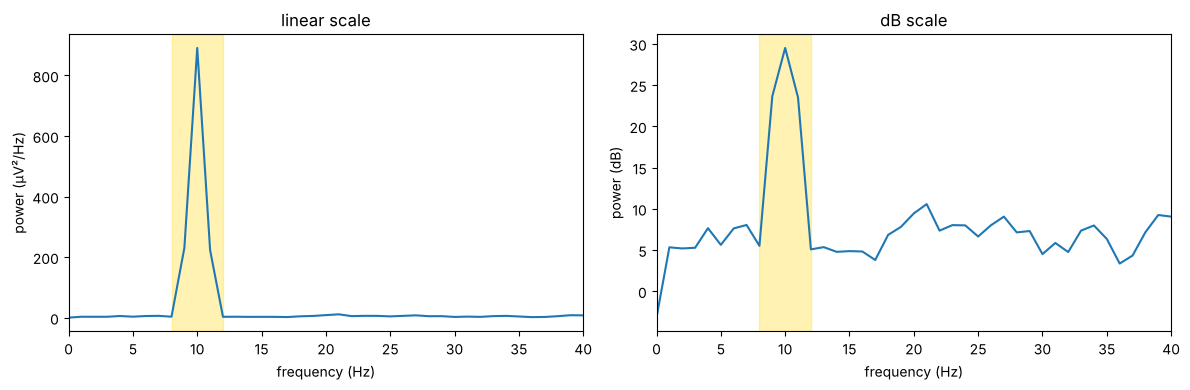

In [3]:
freqs, power = welch(signal, fs=SFREQ, nperseg=SFREQ)  # 1-second windows -> 1 Hz resolution

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(freqs, power)
axes[0].set(xlabel="frequency (Hz)", ylabel="power (µV²/Hz)", title="linear scale")
axes[1].plot(freqs, 10 * np.log10(power))
axes[1].set(xlabel="frequency (Hz)", ylabel="power (dB)", title="dB scale")
for ax in axes:
    ax.axvspan(*ALPHA, color="gold", alpha=0.3)
    ax.set_xlim(0, 40)
fig.tight_layout()

peak = freqs[np.argmax(power)]
print(f"Peak at {peak:.0f} Hz. The wave was at {FREQ} Hz.")

One spike, exactly at `FREQ`. The noise is spread flat over all frequencies: that is the floor the spike stands on.

**Try, one at a time, then run all again:**
- `FREQ = 20`: the spike moves. The spectrum *locates* an oscillation.
- `AMPLITUDE = 10`: the spike shrinks towards the noise floor. With `AMPLITUDE = 2` can you still see it?
- `NOISE = 100`: the floor rises. Is the spike still there in the time plot? In the spectrum?

The last one is the point: in the raw signal the wave disappears under noise long before it disappears from the spectrum.

## 3. Two waves at once

Real EEG contains many rhythms at the same time. The spectrum separates them even when the time plot is unreadable.

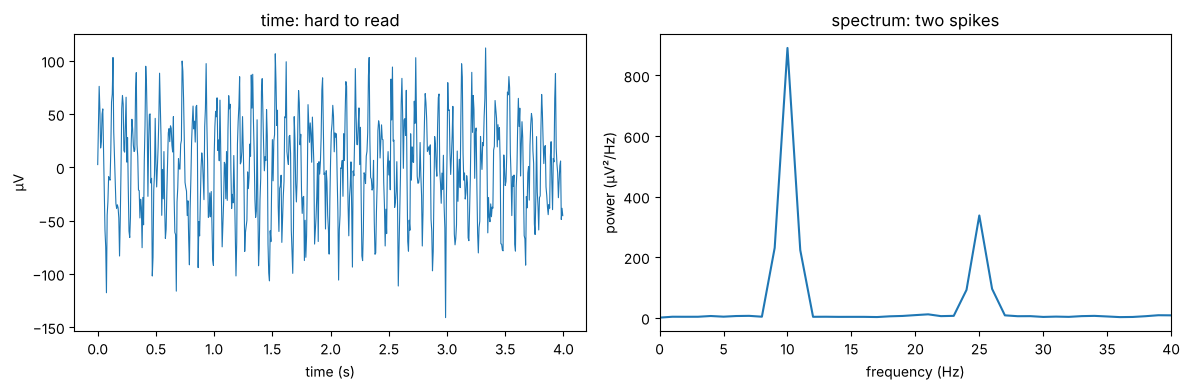

In [4]:
FREQ2, AMPLITUDE2 = 25, 30  # Hz, µV

signal2 = signal + AMPLITUDE2 * np.sin(2 * np.pi * FREQ2 * t)
freqs, power2 = welch(signal2, fs=SFREQ, nperseg=SFREQ)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(t, signal2, lw=0.8)
axes[0].set(xlabel="time (s)", ylabel="µV", title="time: hard to read")
axes[1].plot(freqs, power2)
axes[1].set(xlabel="frequency (Hz)", ylabel="power (µV²/Hz)", title="spectrum: two spikes", xlim=(0, 40))
fig.tight_layout()

## 4. Band power: from a curve to one number

A BCI cannot compare curves. It compares numbers to thresholds.
**Band power** is the mean of the spectrum between two frequencies: here 8–12 Hz, the alpha band.

Below, "eyes closed" is simulated as noise + a 10 Hz wave, "eyes open" as the same noise without the wave.
This is a caricature of what notebook 01 measured on a real head.

In [5]:
in_alpha = (freqs >= ALPHA[0]) & (freqs <= ALPHA[1])

simulated = {
    "eyes open": noise,
    "eyes closed": noise + wave,
}
band_power = {}
for condition, y in simulated.items():
    f, p = welch(y, fs=SFREQ, nperseg=SFREQ)
    band_power[condition] = p[in_alpha].mean()
    print(f"{condition:12s} alpha power {band_power[condition]:7.1f} µV²/Hz")

print(f"\nEyes closed / eyes open: x{band_power['eyes closed'] / band_power['eyes open']:.1f}")

eyes open    alpha power     4.2 µV²/Hz
eyes closed  alpha power   270.4 µV²/Hz

Eyes closed / eyes open: x64.1


## What to remember

- An oscillation at *f* Hz shows up in the spectrum as a spike at *f*. Where the spike is tells the frequency; how tall it is tells the amplitude.
- Noise is spread over all frequencies, so it raises the floor without making a spike.
- The spectrum finds a wave that the eye can no longer see in the raw signal.
- Band power turns the spectrum into one number per band. A threshold on that number is already a one-bit brain switch.
- Notebook 01 is this exact pipeline on real data: eyes closed = noise + a 10 Hz wave over the back of the head.

**Try:** set `AMPLITUDE` so that the simulated ratio in section 4 is about x16, like subject 1 in notebook 01.